# Multi Photopeak Reconstruction

In [1]:
from pytomography import datasets

# The tutorial data: downloaded the first time it runs (see Tutorial data in the docs)
datasets.fetch("SPECT/Lu177-NEMA-SymT2")
DATA = datasets.data_dir()  # the PYTOMOGRAPHY_DATA folder, or ~/pytomography_data
# Results go here, never into the data folder
OUTPUT = datasets.output_dir("SPECT/Lu177-NEMA-SymT2")

SPECT/Lu177-NEMA-SymT2: already downloaded


In [2]:
import os
from pytomography import io
from pytomography.transforms.SPECT import SPECTAttenuationTransform, SPECTPSFTransform
from pytomography.algorithms import OSEM
from pytomography.projectors.SPECT import SPECTSystemMatrix
from pytomography.likelihoods import PoissonLogLikelihood
from pytomography.projectors import ExtendedSystemMatrix
import pytomography
import matplotlib.pyplot as plt
import torch

Change this to the path where you downloaded the PyTomography tutorial data

In [3]:
PATH = DATA / 'SPECT'

In [4]:
path = os.path.join(PATH, 'Lu177-NEMA-SymT2')
path_CT = os.path.join(path, 'CT')
files_CT = [os.path.join(path_CT, file) for file in os.listdir(path_CT)]
file_NM = os.path.join(path, 'projection_data.dcm')

The idea behind dual peak reconstruction is that we will construct two seperate system matrices (one for each peak) and then combine them together. Most of this is similar to the standard DICOM tutorial, but now we're constructing two different system matrices. `io.SPECT.read_dicom` reads every energy window, and `proj_meta.energy_windows` says which is which: As in the DICOM introduction, `read_dicom` puts the grid in the frame of the scan's CT, with the registration of the SPECT to the CT that Siemens records in the projection file.

In [5]:
projections, object_meta, proj_meta = io.SPECT.read_dicom(file_NM)
windows = proj_meta.energy_windows
for i, window in enumerate(windows):
    print(f'Index {i}:   Name: "{window.name}", Energies: {window.lower_keV:.1f}-{window.upper_keV:.1f} keV, photon {window.photon_keV:g} keV')

Index 0:   Name: "Window Group A", Energies: 187.2-228.8 keV, photon 208 keV
Index 1:   Name: "Window Group B", Energies: 166.4-187.2 keV, photon 176.8 keV
Index 2:   Name: "Window Group C", Energies: 228.8-249.6 keV, photon 239.2 keV
Index 3:   Name: "Window Group D", Energies: 101.7-124.3 keV, photon 113 keV
Index 4:   Name: "Window Group E", Energies: 85.9-101.7 keV, photon 93.79 keV
Index 5:   Name: "Window Group F", Energies: 124.3-146.9 keV, photon 135.6 keV


In [6]:
photopeak208 = projections[0]
photopeak113 = projections[3]
scatter208 = io.SPECT.energy_window_scatter(projections, proj_meta, peak=0, lower=1, upper=2)
scatter113 = io.SPECT.energy_window_scatter(projections, proj_meta, peak=3, lower=4, upper=5)
amap208 = io.attenuation_map(files_CT, object_meta, energy_keV=windows[0].photon_keV)
amap113 = io.attenuation_map(files_CT, object_meta, energy_keV=windows[3].photon_keV)
collimator_name = 'SY-ME'
intrinsic_fwhm_140keV_mm = 3.8 # mm at 140 keV
psf_meta208 = io.SPECT.collimator_psf(
    collimator_name,
    windows[0].photon_keV,
    intrinsic_fwhm_140keV_mm=intrinsic_fwhm_140keV_mm
)
psf_meta113 = io.SPECT.collimator_psf(
    collimator_name,
    windows[3].photon_keV,
    intrinsic_fwhm_140keV_mm=intrinsic_fwhm_140keV_mm
)
att_transform208 = SPECTAttenuationTransform(attenuation_map=amap208)
att_transform113 = SPECTAttenuationTransform(attenuation_map=amap113)
psf_transform208 = SPECTPSFTransform(psf_meta=psf_meta208)
psf_transform113 = SPECTPSFTransform(psf_meta=psf_meta113)
system_matrix208 = SPECTSystemMatrix(
    obj2obj_transforms=[att_transform208, psf_transform208],
    proj2proj_transforms=[],
    object_meta=object_meta,
    proj_meta=proj_meta,
)
system_matrix113 = SPECTSystemMatrix(
    obj2obj_transforms=[att_transform113, psf_transform113],
    proj2proj_transforms=[],
    object_meta=object_meta,
    proj_meta=proj_meta,
)

From these two system matrices, we build a single system matrix that simulatenously projects to both peaks at once

* The system matrices need to be scaled by the relative calibration factor in CPS/MBq in order to compensate for differnces in count rate between the two peaks

In [7]:
# These calibration factors are approximate and come from SIMIND
calib208 = 10.2419 # CPS/MBq
calib113 = 11.3 # CPS/MBq

system_matrix = ExtendedSystemMatrix(
    system_matrices= [
        calib113*system_matrix113,
        calib208*system_matrix208
    ] 
)

Now if we create an object and forward project, it will project to both peaks

In [8]:
test_object = torch.zeros(object_meta.shape).to(pytomography.device)
test_object[50:70,50:70,50:70] = 1

In [9]:
test_projections = system_matrix.forward(test_object)
test_projections.shape

torch.Size([2, 96, 128, 128])

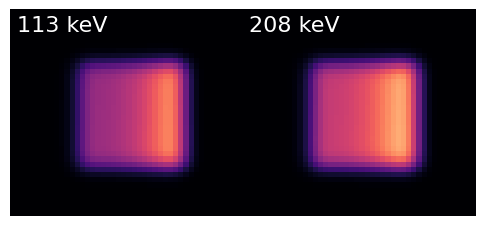

In [10]:
IDX_113 = 0
IDX_208 = 1
test_projection_113 = test_projections[IDX_113][25].cpu().T
test_projection_208 = test_projections[IDX_208][25].cpu().T
fig, ax = plt.subplots(1,2, figsize=(6,3), gridspec_kw={'wspace':0.0})
ax[0].imshow(test_projection_113, cmap='magma', vmax=80)
ax[0].set_xlim(45,90)
ax[0].set_ylim(40,80)
ax[0].axis('off')
ax[0].text(0.03, 0.97, '113 keV', color='white', transform=ax[0].transAxes, ha='left', va='top', fontsize=16)
ax[1].imshow(test_projection_208, cmap='magma', vmax=80)
ax[1].set_xlim(45,90)
ax[1].set_ylim(40,80)
ax[1].axis('off')
ax[1].text(0.03, 0.97, '208 keV', color='white', transform=ax[1].transAxes, ha='left', va='top', fontsize=16)
plt.show()

We can create the likelihood by stacking the photopeak/scatters as well

In [11]:
photopeak = torch.stack([photopeak113, photopeak208], dim=0)
scatter = torch.stack([scatter113, scatter208], dim=0)
likelihood = PoissonLogLikelihood(system_matrix, photopeak, scatter)

Then we reconstruct as normal, after printing the memory the reconstruction will need (`estimate_memory`): the combined system matrix counts both photopeaks.

In [12]:
recon_algo = OSEM(likelihood)
print(recon_algo.estimate_memory(n_subsets=8))
recon_OSEM = recon_algo(n_iters = 8, n_subsets=8)

OSEM (ExtendedSystemMatrix): 8 subsets
Peak ~ 4.5 GB RAM, 1.3 GB GPU (on Windows, GPU memory counts as RAM too)
  held for the whole run: 0.00 GB RAM, 0.2 GB GPU (image 0.01 GPU, H_m^T 1 of 8 subsets 0.1 GPU, images of an update 0.03 GPU, rotation grids of every view (cached) 0.1 GPU, what the object transforms keep 0.01 GPU, system matrix 2: what it holds 0.01 GPU, projections (the data) 0.01 GPU, additive term 0.01 GPU)
  one subset at a time: 0.00 GB RAM, 0.1 GB GPU (projections of a subset: measured, expected, additive term, of ones, padded copy, for each of 2, kept and stacked 0.03 GPU, padded object, support and sum of a projection 0.1 GPU, projections of ones of all 2 (for H^T 1) 0.01 GPU)
  projector chunks: 0.00 GB RAM, 0.1 GB GPU (one view: rotated object and the transforms' temporaries 0.1 GPU)
  Python, CUDA, allocator: 3.2 GB RAM, 0.9 GB GPU (Python, PyTorch and CUDA 3.0 RAM, CUDA context and libraries on the GPU (outside PyTorch) 0.7 GPU, PyTorch's GPU cache (rounded and 

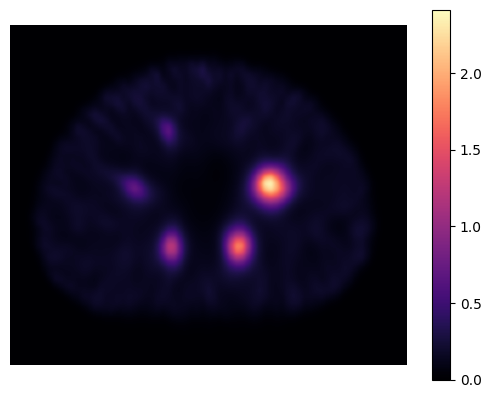

In [13]:
plt.imshow(recon_OSEM[:,:,61].cpu().T, cmap='magma', interpolation='gaussian')
plt.xlim(30,100)
plt.ylim(100,40)
plt.axis('off')
plt.colorbar()
plt.show()

You may wonder what the units are above. Since we scaled the system matrix by factors with units of Counts / second / MBq, the image has units of MBq $\cdot$ seconds. Why?:
* Image $\times$ system matrix = projections and projecitons have units of counts

So we can convert our image to units of MBq by diving by time, which in this case is the measured time per projection (15 s), which `proj_meta` keeps for every view:

In [14]:
float(proj_meta.frame_duration_s[0])  # seconds

15.002

## Save the images

`io.save_dicom` writes the reconstruction as a DICOM nuclear medicine (NM) file, in MBq·s and in its place in the patient (`object_meta.affine`). `reference=file_NM` gives it the patient and study of the projections, so DICOM viewers show it with the scan's CT.

In [15]:
saved = io.save_dicom(recon_OSEM, OUTPUT / 't_dualpeak' / 'osem', object_meta, reference=file_NM, units='MBq.s',
                      series_description='OSEM 8x8, 113 and 208 keV', overwrite=True)